# Classical AI: Adversarial Search and Games

> **Who is this for:** a beginner who has finished [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb) and knows high-school maths, or a university student revising game search for an exam or an interview.
>
> **What you will learn**
> - How to describe a game as a search problem: zero-sum, perfect information, game trees, utility
> - **Minimax**, traced step by step on a small tree, then a perfect tic-tac-toe player (and a check that perfect play is a draw)
> - **Alpha-beta pruning**: which branches get cut, how many nodes it saves, and why **move ordering** matters
> - **Depth-limited search with an evaluation function**: a Connect-4 player, with win rates against weaker opponents
> - **Expectimax** for games with dice
> - **Monte Carlo Tree Search (UCT)** from scratch, compared with alpha-beta
> - The real story of Deep Blue, AlphaGo, AlphaZero and MuZero
>
> **Prerequisites:** [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb). Depth-first search and recursion from the earlier notebooks of this module ([`02_uninformed_search.ipynb`](02_uninformed_search.ipynb)) help.
>
> **Time needed:** about 2 to 2.5 hours (the code runs in about a minute).
>
> **Runs on:** CPU, no API key. Only Python, numpy, pandas, matplotlib and networkx.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; it is recommended for BS/MS AI students and for interview prep. You can skip it and still follow the rest of the repo.

## Explained simply

Some problems have an opponent who fights back: chess, Connect-4, even haggling over a price. You cannot just plan your own moves; for every move you must ask "and what is their best reply?" **Minimax** is the rule "assume the other player is as clever as possible, and choose the move whose *worst* outcome is the best". In chess this is the familiar "if I take that pawn, they take my queen, so I won't". In a price negotiation, you plan your offer by imagining the toughest reply the seller could make. Computers do this by drawing a tree of all moves and replies; the tricks in this notebook (pruning, depth limits, random playouts) make that tree small enough to search. The same ideas, combined with neural networks, are what made AlphaGo beat the world's best Go players.

**Tiny example.** You pick one of two boxes; then your rival picks which coin *from that box* you get, and they want you to get as little as possible. Box 1 holds £1 and £10. Box 2 holds £4 and £5. If you grab Box 1 dreaming of £10, your rival hands you £1. If you pick Box 2, the worst you get is £4. Minimax picks **Box 2**: worst case £4 beats worst case £1.

**In one line**

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Minimax | assume the opponent plays perfectly; pick the move with the best worst case | chess and checkers programs |
| Alpha-beta pruning | skip moves that cannot change the decision | every strong chess engine, e.g. Stockfish |
| Monte Carlo Tree Search | play many quick random games and focus on the moves that win most | AlphaGo, AlphaZero, game AI |

## 1. Games as search

*In plain words: a game is a search problem where every other move is chosen by someone trying to beat you.*

In the earlier search notebooks there was one agent and a passive world. In a **game**, another agent (the **opponent**) moves too, and it is trying to make you lose. You cannot plan a fixed path; you need a **strategy** that says what to do for every possible reply.

*Everyday analogy:* planning a road trip is ordinary search. Planning a chess move is like planning a road trip where somebody else controls half of the traffic lights and wants you to be late.

### Kinds of games

| | **Deterministic** | **Chance** (dice, shuffled cards) |
|---|---|---|
| **Perfect information** (everyone sees the whole state) | chess, checkers, Go, Othello, tic-tac-toe, Connect-4 | backgammon, Monopoly |
| **Imperfect information** (some state is hidden) | Battleship, Stratego, Kriegspiel | poker, bridge, Scrabble |

This notebook focuses on **two-player, turn-taking, zero-sum games of perfect information**, and adds chance in Section 6.

- **Zero-sum** (more precisely *constant-sum*): what one player wins, the other loses. The utilities of the two players add up to the same constant in every outcome (e.g. +1 / -1, or 1 / 0 / ½ for win / loss / draw). So one number, "how good for MAX", describes the outcome for both.
- **Perfect information**: both players see the full state (no hidden cards).

### Formal definition (AIMA 4th ed., Section 5.1)

| Element | Meaning | Tic-tac-toe |
|---|---|---|
| $S_0$ | initial state | empty board |
| $\text{TO-MOVE}(s)$ | whose turn it is | X if both have the same number of marks, else O |
| $\text{ACTIONS}(s)$ | legal moves | the empty squares |
| $\text{RESULT}(s, a)$ | transition model | the board with the new mark |
| $\text{IS-TERMINAL}(s)$ | is the game over? | three in a row, or board full |
| $\text{UTILITY}(s, p)$ | final payoff for player $p$ | +1 win, 0 draw, -1 loss |

We call the two players **MAX** (moves first, wants a high utility) and **MIN** (wants a low utility). In tic-tac-toe, X is MAX.

The **game tree** has the initial state at the root, one child per legal move, and terminal states at the leaves. One move by one player is a **ply**; a full "move" in chess is two plies.

In [1]:
# Setup: imports used throughout the notebook
import math, random, time, itertools
from functools import lru_cache                 # memoisation (caching) of function results
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx                           # for drawing small game trees

random.seed(0); np.random.seed(0)
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 140)
NOTEBOOK_START = time.time()
print("ready")

ready


In [2]:
# ---- Tic-tac-toe: the game definition, exactly the six elements of the table above ----
EMPTY_BOARD = (" ",) * 9                                   # S0: squares 0..8, row by row
LINES = [(0, 1, 2), (3, 4, 5), (6, 7, 8), (0, 3, 6), (1, 4, 7), (2, 5, 8), (0, 4, 8), (2, 4, 6)]

def winner(b):
    # 'X' or 'O' if that player has three in a row, else None
    for i, j, k in LINES:
        if b[i] != " " and b[i] == b[j] == b[k]:
            return b[i]
    return None

def to_move(b):                     # TO-MOVE: X moves when both have the same number of marks
    return "X" if b.count("X") == b.count("O") else "O"

def actions(b):                     # ACTIONS: indices of empty squares
    return [i for i in range(9) if b[i] == " "]

def result(b, a):                   # RESULT: place the current player's mark on square a
    return b[:a] + (to_move(b),) + b[a + 1:]

def is_terminal(b):                 # IS-TERMINAL: someone won or the board is full
    return winner(b) is not None or " " not in b

def utility(b):                     # UTILITY for MAX (= X): +1, 0 or -1
    w = winner(b)
    return 1 if w == "X" else (-1 if w == "O" else 0)

def show(b):
    # pretty-print a board; empty squares show their index so you can see the move numbers
    cells = [b[i] if b[i] != " " else str(i) for i in range(9)]
    return "\n".join(" " + " | ".join(cells[r * 3:r * 3 + 3]) for r in range(3))

print(show(EMPTY_BOARD))

# How big is the tic-tac-toe game tree?
# The subtree below a board depends only on the board, so we can count it recursively and cache the
# answer per board (lru_cache). This counts the full tree without walking all of it.
@lru_cache(maxsize=None)
def count_tree(b):
    # returns (number of nodes, number of terminal leaves) in the game tree below board b
    if is_terminal(b):
        return 1, 1
    nodes, leaves = 1, 0
    for a in actions(b):
        n, l = count_tree(result(b, a))
        nodes += n; leaves += l
    return nodes, leaves

stats = dict(zip(["nodes", "terminal games"], count_tree(EMPTY_BOARD)))

# Distinct positions reachable from the empty board (the same board can be reached by different move orders)
reachable = set()
stack = [EMPTY_BOARD]
while stack:
    b = stack.pop()
    if b in reachable:
        continue
    reachable.add(b)
    if not is_terminal(b):
        stack.extend(result(b, a) for a in actions(b))
ALL_STATES = sorted(reachable)                        # sorted list: a fixed, reproducible order
print(f"nodes in the full game tree:  {stats['nodes']:,}")
print(f"complete games (leaves):      {stats['terminal games']:,}")
print(f"distinct reachable positions: {len(ALL_STATES):,}")
assert stats["nodes"] == 549_946 and stats["terminal games"] == 255_168 and len(ALL_STATES) == 5_478

 0 | 1 | 2
 3 | 4 | 5
 6 | 7 | 8


nodes in the full game tree:  549,946
complete games (leaves):      255,168
distinct reachable positions: 5,478


**What just happened?** We coded the six elements of the game and counted the entire game tree (plain minimax below will walk all of it and confirm the count). The numbers match the known values: **549,946 nodes**, **255,168 different complete games**, but only **5,478 distinct positions** (many move orders lead to the same board). A tree that repeats states is wasteful, which is why game programs use **transposition tables** (a cache of positions already evaluated).

For comparison: chess has an average branching factor of about 35 and games of about 80 plies, so its game tree has roughly $35^{80} \approx 10^{123}$ nodes (Shannon estimated about $10^{120}$ in 1950), with around $10^{44}$ legal positions. Go has about $2 \times 10^{170}$ legal positions. Brute force is impossible there; everything in this notebook is about searching smarter.

## 2. Minimax

*In plain words: score each move by what happens if both sides play their best from then on.*

**Idea:** assume both players play perfectly. MAX picks the move with the highest value; MIN picks the move with the lowest value. The **minimax value** of a state is the utility MAX gets if both play optimally from there:

$$
\text{MINIMAX}(s) =
\begin{cases}
\text{UTILITY}(s, \text{MAX}) & \text{if IS-TERMINAL}(s) \\
\max_{a} \text{MINIMAX}(\text{RESULT}(s, a)) & \text{if TO-MOVE}(s) = \text{MAX} \\
\min_{a} \text{MINIMAX}(\text{RESULT}(s, a)) & \text{if TO-MOVE}(s) = \text{MIN}
\end{cases}
$$

The values are computed **bottom-up**: leaves first, then their parents, all the way to the root. The search itself is a depth-first traversal.

### Worked example by hand (AIMA Figure 5.2)

MAX moves at the root A; MIN replies at B, C or D; the leaves hold utilities for MAX.

```
                         A  (MAX)
          a1 /           | a2            \ a3
          B (MIN)        C (MIN)          D (MIN)
        /   |   \      /   |   \        /   |   \
       3    12   8    2    4    6     14    5    2

  B = min(3, 12, 8) = 3      C = min(2, 4, 6) = 2      D = min(14, 5, 2) = 2
  A = max(3, 2, 2) = 3   ->  MAX plays a1
```

MAX cannot get 14 (in D's subtree), because MIN would answer with 2. The best MAX can **guarantee** is 3.

In [3]:
# The example tree as plain dictionaries
TREE = {"A": ["B", "C", "D"], "B": ["B1", "B2", "B3"], "C": ["C1", "C2", "C3"], "D": ["D1", "D2", "D3"]}
LEAF = {"B1": 3, "B2": 12, "B3": 8, "C1": 2, "C2": 4, "C3": 6, "D1": 14, "D2": 5, "D3": 2}

def minimax_traced(node, is_max, trace, depth=0):
    # plain minimax that writes every step into `trace`
    if node in LEAF:                                              # terminal: return its utility
        trace.append({"step": len(trace) + 1, "node": "  " * depth + node, "event": "leaf", "value": LEAF[node]})
        return LEAF[node]
    trace.append({"step": len(trace) + 1, "node": "  " * depth + node, "event": "enter " + ("MAX" if is_max else "MIN"), "value": ""})
    values = [minimax_traced(child, not is_max, trace, depth + 1) for child in TREE[node]]
    v = max(values) if is_max else min(values)                    # MAX takes the max, MIN the min
    trace.append({"step": len(trace) + 1, "node": "  " * depth + node,
                  "event": f"{'max' if is_max else 'min'}{tuple(values)}", "value": v})
    return v

trace = []
root_value = minimax_traced("A", True, trace)
display(pd.DataFrame(trace).set_index("step"))
print("minimax value of A =", root_value)
assert root_value == 3

,node,event,value
step,,,
1,A,enter MAX,
2,B,enter MIN,
3,B1,leaf,3
4,B2,leaf,12
5,B3,leaf,8
6,B,"min(3, 12, 8)",3
7,C,enter MIN,
8,C1,leaf,2
9,C2,leaf,4


minimax value of A = 3


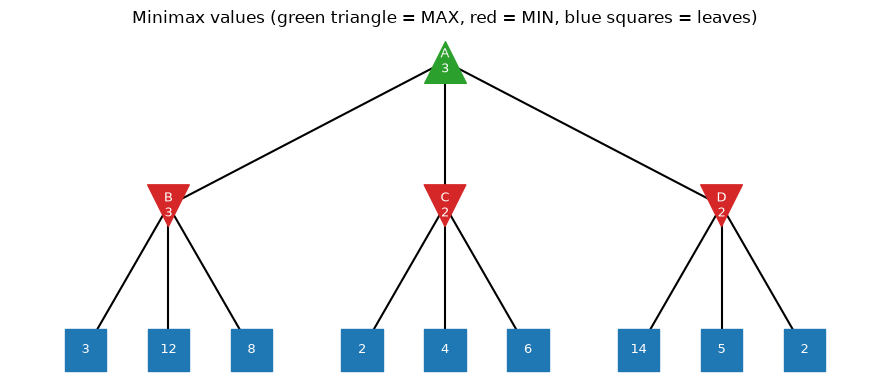

In [4]:
def draw_tree(ax, values, title, pruned=frozenset()):
    # draw the example tree; MAX = up triangle, MIN = down triangle, leaves = squares; pruned edges dashed
    pos = {"A": (0, 2), "B": (-3, 1), "C": (0, 1), "D": (3, 1)}
    for k, parent in enumerate(["B", "C", "D"]):
        for i, leaf in enumerate(TREE[parent]):
            pos[leaf] = (pos[parent][0] + (i - 1) * 0.9, 0)
    G = nx.DiGraph([(p, c) for p, cs in TREE.items() for c in cs])
    normal = [(u, v) for u, v in G.edges if v not in pruned]
    cut = [(u, v) for u, v in G.edges if v in pruned]
    nx.draw_networkx_edges(G, pos, edgelist=normal, ax=ax, arrows=False, width=1.5)
    nx.draw_networkx_edges(G, pos, edgelist=cut, ax=ax, arrows=False, style="dashed", edge_color="lightgray")
    for nodes, shape, colour in [(["A"], "^", "tab:green"), (["B", "C", "D"], "v", "tab:red"), (list(LEAF), "s", "tab:blue")]:
        colours = ["lightgray" if n in pruned else colour for n in nodes]
        nx.draw_networkx_nodes(G, pos, nodelist=nodes, node_shape=shape, node_color=colours, node_size=900, ax=ax)
    labels = {n: str(LEAF[n]) if n in LEAF else (f"{n}\n{values[n]}" if n in values else n) for n in G.nodes}
    nx.draw_networkx_labels(G, pos, labels, font_size=9, font_color="white", ax=ax)
    ax.set_title(title); ax.axis("off")

def all_minimax_values(node="A", is_max=True, out=None):
    out = {} if out is None else out
    if node in LEAF:
        out[node] = LEAF[node]
    else:
        vals = [all_minimax_values(c, not is_max, out)[c] for c in TREE[node]]
        out[node] = max(vals) if is_max else min(vals)
    return out

fig, ax = plt.subplots(figsize=(9, 4))
draw_tree(ax, all_minimax_values(), "Minimax values (green triangle = MAX, red = MIN, blue squares = leaves)")
plt.tight_layout(); plt.show()

**What just happened?** The trace table shows the depth-first order: enter A, enter B, read its three leaves, compute $B = \min(3, 12, 8) = 3$, then C, then D, and finally $A = \max(3, 2, 2) = 3$. Indentation shows depth.

**Complexity.** For maximum depth $m$ and $b$ legal moves per state, minimax visits every node: time $O(b^m)$, space $O(bm)$ (depth-first, one path plus the siblings along it), or $O(m)$ if moves are generated one at a time. Minimax is **complete** (if the tree is finite) and **optimal** against an optimal opponent.

### A perfect tic-tac-toe player

Plain minimax on tic-tac-toe visits all 549,946 nodes. Because there are only 5,478 distinct positions, we can also **memoise** (cache) the value of every position: then each position is solved once. Both must give the same answers, and we check that.

In [5]:
def minimax_plain(b, counter):
    # brute-force minimax with no tricks at all; counts the nodes it visits
    counter["nodes"] += 1
    if is_terminal(b):
        return utility(b)
    values = [minimax_plain(result(b, a), counter) for a in actions(b)]
    return max(values) if to_move(b) == "X" else min(values)

@lru_cache(maxsize=None)
def solve(b):
    # the same minimax, but each position is computed once and cached (a transposition table)
    if is_terminal(b):
        return utility(b)
    values = [solve(result(b, a)) for a in actions(b)]
    return max(values) if to_move(b) == "X" else min(values)

t0 = time.perf_counter()
counter = Counter()
v_plain = minimax_plain(EMPTY_BOARD, counter)
t_plain = time.perf_counter() - t0
t0 = time.perf_counter()
v_memo = solve(EMPTY_BOARD)
t_memo = time.perf_counter() - t0
print(f"plain minimax:    value {v_plain}, {counter['nodes']:,} nodes, {t_plain:.2f} s")
print(f"memoised minimax: value {v_memo}, {solve.cache_info().currsize:,} positions cached, {t_memo:.3f} s")
assert v_plain == v_memo == 0                  # tic-tac-toe is a draw with perfect play
assert counter["nodes"] == 549_946             # plain minimax visits the whole game tree

# brute-force check on many positions: plain minimax and the cached solver agree
check_rng = random.Random(1)
for b in check_rng.sample([s for s in ALL_STATES if s.count(" ") <= 7], 300):
    assert minimax_plain(b, Counter()) == solve(b)
print("plain minimax == cached minimax on 300 random positions")

values = Counter(solve(b) for b in ALL_STATES)
print("value of the 5,478 positions (X's view):", {"X wins": values[1], "draw": values[0], "O wins": values[-1]})

plain minimax:    value 0, 549,946 nodes, 11.37 s
memoised minimax: value 0, 5,478 positions cached, 0.176 s


plain minimax == cached minimax on 300 random positions
value of the 5,478 positions (X's view): {'X wins': 2936, 'draw': 1068, 'O wins': 1474}


In [6]:
def perfect_agent(b, rng=None):
    # choose a move with the best minimax value for the player to move (random among equals)
    acts = actions(b)
    vals = {a: solve(result(b, a)) for a in acts}
    target = max(vals.values()) if to_move(b) == "X" else min(vals.values())
    best = [a for a in acts if vals[a] == target]
    return rng.choice(best) if rng else best[0]

def random_agent(b, rng):
    return rng.choice(actions(b))

def play_ttt(agent_x, agent_o, rng, verbose=False):
    # play one game; returns the final board
    b = EMPTY_BOARD
    while not is_terminal(b):
        agent = agent_x if to_move(b) == "X" else agent_o
        b = result(b, agent(b, rng))
    if verbose:
        print(show(b)); print("winner:", winner(b) or "draw")
    return b

# Perfect vs perfect: always a draw
rng = random.Random(0)
print("perfect X vs perfect O:")
final = play_ttt(perfect_agent, perfect_agent, rng, verbose=True)
for _ in range(50):
    assert utility(play_ttt(perfect_agent, perfect_agent, rng)) == 0

# Perfect vs random: the perfect player never loses
rows = []
for perfect_is in ("X", "O"):
    outcomes = Counter()
    for _ in range(200):
        if perfect_is == "X":
            u = utility(play_ttt(perfect_agent, random_agent, rng))
        else:
            u = -utility(play_ttt(random_agent, perfect_agent, rng))
        outcomes[{1: "win", 0: "draw", -1: "loss"}[u]] += 1
    assert outcomes["loss"] == 0
    rows.append({"perfect player plays": perfect_is, "games": 200, **{k: outcomes[k] for k in ("win", "draw", "loss")}})
display(pd.DataFrame(rows))

perfect X vs perfect O:
 X | O | X
 O | O | X
 X | X | O
winner: draw


,perfect player plays,games,win,draw,loss
0,X,200,194,6,0
1,O,200,155,45,0


**What just happened?**
- Plain minimax and the cached version both say the empty board is worth **0**: with perfect play, tic-tac-toe is a **draw**. Plain minimax visited all 549,946 nodes; the cached version solved each of the 5,478 positions once and was far faster.
- We checked plain (brute-force) minimax against the cached solver on 300 random positions: identical.
- 50 games of perfect vs perfect were all draws, and the perfect player never lost to a random player (it wins most games, especially when it moves first).

> ⚠️ **Common mistake:** writing `to_move` wrongly (for example, alternating by depth but starting with O) so that MAX and MIN are swapped. Always check the root value of a known game (tic-tac-toe = draw) and play a few games against a random player.

## 3. Alpha-beta pruning

*In plain words: stop looking at a move as soon as you know it is worse than one you already have.*

Minimax looks at every node, but many of them cannot change the decision. **Alpha-beta pruning** computes **exactly the same minimax value** while skipping such subtrees.

- **$\alpha$** = the best value MAX can already guarantee on the path so far (a lower bound; starts at $-\infty$).
- **$\beta$** = the best (lowest) value MIN can already guarantee on the path so far (an upper bound; starts at $+\infty$).
- At a MIN node, as soon as its value drops to $\le \alpha$, stop: MAX will never let the game reach it (MAX already has something at least as good elsewhere). This is an **alpha cut-off**.
- At a MAX node, as soon as its value rises to $\ge \beta$, stop: MIN will never allow it. This is a **beta cut-off**.

### Hand trace on the example tree (AIMA Figure 5.5)

| Step | Where | What we learn | α, β at that node |
|---|---|---|---|
| 1 | B sees 3 | B ≤ 3 | α = −∞, β = 3 |
| 2 | B sees 12, 8 | B = 3, so A ≥ 3 | A: α = 3 |
| 3 | C sees 2 | C ≤ 2, but A already has 3 | C's value v = 2 ≤ α = 3: **prune C's other leaves (4 and 6)** |
| 4 | D sees 14, 5, 2 | D = 2 | no cut: 14 and 5 are both above α = 3 |
| 5 | A | A = max(3, ≤2, 2) = 3 | same answer as minimax |

Note that C's real value is 2, but alpha-beta only learns "C ≤ 2", which is enough: it cannot beat 3.

,node,event,value,alpha,beta
0,B1,leaf,3,-inf,inf
1,B,after child B1,3,-inf,3.0
2,B2,leaf,12,-inf,3.0
3,B,after child B2,3,-inf,3.0
4,B3,leaf,8,-inf,3.0
5,B,after child B3,3,-inf,3.0
6,A,after child B,3,3.0,inf
7,C1,leaf,2,3.0,inf
8,C,alpha cut-off (v=2 <= alpha=3),2,3.0,inf
9,A,after child C,3,3.0,inf


alpha-beta value of A = 3 | pruned leaves: ['C2', 'C3'] | leaves examined: 7 of 9


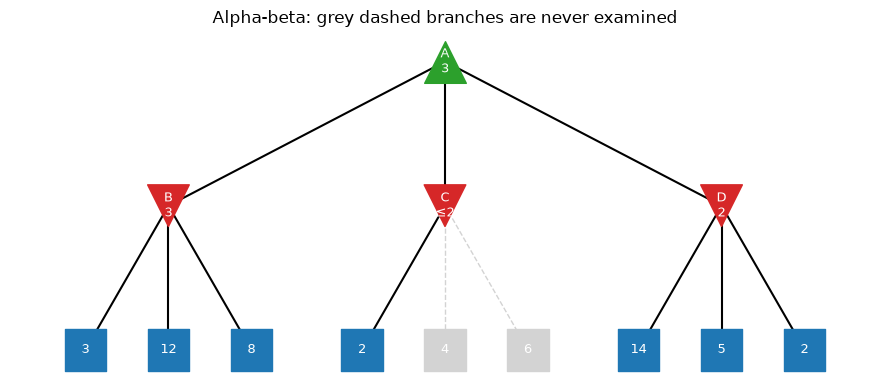

In [7]:
def alphabeta_traced(node, is_max, alpha, beta, trace, visited, depth=0):
    # alpha-beta on the example tree, writing each step into `trace` and each visited node into `visited`
    visited.append(node)
    pad = "  " * depth
    if node in LEAF:
        trace.append({"node": pad + node, "event": "leaf", "value": LEAF[node], "alpha": alpha, "beta": beta})
        return LEAF[node]
    v = -math.inf if is_max else math.inf
    for child in TREE[node]:
        cv = alphabeta_traced(child, not is_max, alpha, beta, trace, visited, depth + 1)
        if is_max:
            v = max(v, cv)
            if v >= beta:                                  # MIN above will never allow this
                trace.append({"node": pad + node, "event": f"beta cut-off (v={v} >= beta={beta})", "value": v, "alpha": alpha, "beta": beta})
                return v
            alpha = max(alpha, v)
        else:
            v = min(v, cv)
            if v <= alpha:                                 # MAX above already has something better
                trace.append({"node": pad + node, "event": f"alpha cut-off (v={v} <= alpha={alpha})", "value": v, "alpha": alpha, "beta": beta})
                return v
            beta = min(beta, v)
        trace.append({"node": pad + node, "event": f"after child {child}", "value": v, "alpha": alpha, "beta": beta})
    return v

ab_trace, visited = [], []
v = alphabeta_traced("A", True, -math.inf, math.inf, ab_trace, visited)
display(pd.DataFrame(ab_trace))
pruned = frozenset(n for n in list(LEAF) + list(TREE) if n not in visited)
print("alpha-beta value of A =", v, "| pruned leaves:", sorted(pruned), "| leaves examined:", sum(n in LEAF for n in visited), "of 9")
assert v == root_value == 3 and pruned == {"C2", "C3"}

ab_values = {n: (LEAF[n] if n in LEAF else None) for n in visited}
ab_values.update({"A": 3, "B": 3, "C": "≤2", "D": 2})
fig, ax = plt.subplots(figsize=(9, 4))
draw_tree(ax, ab_values, "Alpha-beta: grey dashed branches are never examined", pruned=pruned)
plt.tight_layout(); plt.show()

**What just happened?** The table follows the hand trace. At C, the first leaf (2) already makes C's value $\le 2 \le \alpha = 3$, so leaves C2 and C3 are pruned (grey in the picture). The root value is still 3.

### Move ordering

How much alpha-beta prunes depends on the **order** in which moves are tried. If D's leaves were ordered (2, 5, 14) instead of (14, 5, 2), D would be cut off after its first leaf too. With **perfect ordering** (best move first everywhere), alpha-beta examines about $O(b^{m/2})$ nodes instead of $O(b^m)$: the **effective branching factor** drops from $b$ to $\sqrt{b}$, so in the same time you can search **twice as deep**. With random ordering it is about $O(b^{3m/4})$. With the worst ordering it prunes very little.

The exact best case is known (Knuth & Moore, 1975): on a uniform tree with branching factor $b$ and depth $d$, perfectly ordered alpha-beta examines exactly $b^{\lceil d/2 \rceil} + b^{\lfloor d/2 \rfloor} - 1$ leaves. Let us test that on random trees.

In [8]:
def random_game_tree(b, d, seed):
    # leaf values of a uniform tree, plus the true minimax value of every node (MAX at even depths)
    leaves = np.random.default_rng(seed).random(b ** d)           # distinct random floats: no ties
    values = [None] * (d + 1)
    values[d] = leaves
    for k in range(d - 1, -1, -1):                                # bottom-up minimax
        grouped = values[k + 1].reshape(-1, b)
        values[k] = grouped.max(axis=1) if k % 2 == 0 else grouped.min(axis=1)
    return values

def alphabeta_tree(values, b, d, k, i, alpha, beta, order, counter):
    # alpha-beta on the uniform tree; node = (depth k, index i); children of (k, i) are (k+1, i*b + j)
    if k == d:
        counter[0] += 1                                           # count leaf evaluations
        return values[d][i]
    kids = [i * b + j for j in range(b)]
    is_max = (k % 2 == 0)
    if order == "best":                                           # best child first (needs the true values)
        kids.sort(key=lambda c: values[k + 1][c], reverse=is_max)
    elif order == "worst":
        kids.sort(key=lambda c: values[k + 1][c], reverse=not is_max)
    v = -math.inf if is_max else math.inf
    for c in kids:
        cv = alphabeta_tree(values, b, d, k + 1, c, alpha, beta, order, counter)
        if is_max:
            v = max(v, cv)
            if v >= beta: return v
            alpha = max(alpha, v)
        else:
            v = min(v, cv)
            if v <= alpha: return v
            beta = min(beta, v)
    return v

rows = []
for b, d in [(3, 6), (4, 6), (5, 5), (8, 4)]:
    for order in ("worst", "natural (random)", "best"):
        leaf_counts = []
        for seed in range(20):
            values = random_game_tree(b, d, seed)
            counter = [0]
            v = alphabeta_tree(values, b, d, 0, 0, -math.inf, math.inf, order.split()[0], counter)
            assert v == values[0][0]                              # same value as full minimax, always
            leaf_counts.append(counter[0])
        rows.append({"b": b, "d": d, "ordering": order, "minimax leaves b^d": b ** d,
                     "alpha-beta leaves (mean of 20 trees)": float(np.mean(leaf_counts))})
    knuth_moore = b ** math.ceil(d / 2) + b ** (d // 2) - 1
    assert rows[-1]["alpha-beta leaves (mean of 20 trees)"] == knuth_moore   # perfect ordering hits the formula
    rows[-1]["Knuth-Moore b^ceil(d/2)+b^floor(d/2)-1"] = knuth_moore
ordering_df = pd.DataFrame(rows).fillna("")
display(ordering_df)

,b,d,ordering,minimax leaves b^d,alpha-beta leaves (mean of 20 trees),Knuth-Moore b^ceil(d/2)+b^floor(d/2)-1
0,3,6,worst,729,660.75,
1,3,6,natural (random),729,284.20,
2,3,6,best,729,53.00,53.0
3,4,6,worst,4096,3563.05,
4,4,6,natural (random),4096,951.60,
5,4,6,best,4096,127.00,127.0
6,5,5,worst,3125,2855.45,
7,5,5,natural (random),3125,838.40,
8,5,5,best,3125,149.00,149.0
9,8,4,worst,4096,3896.65,


**What just happened?** On every random tree, alpha-beta returned exactly the minimax value (checked with `assert`). With **worst** ordering it still examined most of the leaves (for example about 661 of 729 for $b = 3, d = 6$); with **best** ordering it examined exactly the Knuth-Moore number of leaves (for $b = 4, d = 6$: 127 instead of 4,096); random ordering lands in between.

In real programs we do not know the best move in advance (that is what we are searching for), so we use cheap guesses: try captures first in chess, try the centre first in tic-tac-toe and Connect-4, try the move that was best in the previous, shallower iteration (**iterative deepening**), or try "killer moves" that caused cut-offs elsewhere.

Now on the real tic-tac-toe tree:

In [9]:
def alphabeta(b, alpha, beta, counter, order):
    # alpha-beta minimax for tic-tac-toe (X = MAX); `order(b)` returns the moves in the order to try them
    counter["nodes"] += 1
    if is_terminal(b):
        return utility(b)
    if to_move(b) == "X":
        v = -math.inf
        for a in order(b):
            v = max(v, alphabeta(result(b, a), alpha, beta, counter, order))
            if v >= beta:
                return v                          # beta cut-off
            alpha = max(alpha, v)
    else:
        v = math.inf
        for a in order(b):
            v = min(v, alphabeta(result(b, a), alpha, beta, counter, order))
            if v <= alpha:
                return v                          # alpha cut-off
            beta = min(beta, v)
    return v

PREFERENCE = [4, 0, 2, 6, 8, 1, 3, 5, 7]          # centre, then corners, then edges
orders = {
    "natural (0, 1, ..., 8)": actions,
    "heuristic (centre, corners, edges)": lambda b: [a for a in PREFERENCE if b[a] == " "],
    "perfect (best move first, uses solve)": lambda b: sorted(actions(b), key=lambda a: solve(result(b, a)),
                                                             reverse=(to_move(b) == "X")),
    "worst (worst move first)": lambda b: sorted(actions(b), key=lambda a: solve(result(b, a)),
                                                 reverse=(to_move(b) == "O")),
}
rows = [{"method": "plain minimax", "nodes visited": 549_946, "value": 0}]
for name, order in orders.items():
    c = Counter()
    v = alphabeta(EMPTY_BOARD, -math.inf, math.inf, c, order)
    assert v == 0
    rows.append({"method": "alpha-beta, " + name, "nodes visited": c["nodes"], "value": v})
ttt_ab = pd.DataFrame(rows)
ttt_ab["% of minimax"] = (100 * ttt_ab["nodes visited"] / 549_946).round(2)
display(ttt_ab)

# Brute-force check: alpha-beta gives the exact minimax value on all 5,478 positions
for b in ALL_STATES:
    assert alphabeta(b, -math.inf, math.inf, Counter(), actions) == solve(b)
print("alpha-beta == minimax on all", len(ALL_STATES), "reachable positions")

,method,nodes visited,value,% of minimax
0,plain minimax,549946,0,100.00
1,"alpha-beta, natural (0, 1, ..., 8)",18297,0,3.33
2,"alpha-beta, heuristic (centre, corners, edges)",7275,0,1.32
3,"alpha-beta, perfect (best move first, uses solve)",2312,0,0.42
4,"alpha-beta, worst (worst move first)",198837,0,36.16


alpha-beta == minimax on all 5478 reachable positions


**What just happened?** Alpha-beta found the same value (0, a draw) while visiting only a small percentage of the 549,946 nodes: 18,297 nodes (3.3%) in the natural order. Ordering matters a lot: the centre-first heuristic needs 7,275 nodes, perfect ordering only 2,312, and the worst ordering 198,837. Then we checked alpha-beta against minimax on **every** reachable position.

> 🎓 **Exam / interview tip:** "Does alpha-beta change the result?" No. At the root it returns exactly the minimax value; it only skips work. Inside the tree, a pruned node's returned value is only a **bound** (like "C ≤ 2"), not its exact value. Best case $O(b^{m/2})$, random ordering about $O(b^{3m/4})$, worst case $O(b^m)$; space $O(bm)$.

## 4. Depth-limited search and evaluation functions: Connect-4

*In plain words: look only a few moves ahead, then guess how good the position is with a scoring rule.*

Even with alpha-beta, chess or Go trees are far too deep to reach the end of the game. Claude Shannon's 1950 answer: **cut off** the search at a fixed depth and replace the true utility with an **evaluation function** $\text{EVAL}(s)$, an estimate of how good the position is.

$$
\text{H-MINIMAX}(s, d) =
\begin{cases}
\text{EVAL}(s) & \text{if IS-CUTOFF}(s, d) \text{ (e.g. depth limit reached or game over)} \\
\max_a \text{H-MINIMAX}(\text{RESULT}(s, a), d + 1) & \text{MAX to move} \\
\min_a \text{H-MINIMAX}(\text{RESULT}(s, a), d + 1) & \text{MIN to move}
\end{cases}
$$

A good evaluation function: (1) agrees with the utility on terminal states, (2) is fast, and (3) is strongly correlated with the chance of winning. Classic evaluation functions are **weighted linear functions of features**: $\text{EVAL}(s) = w_1 f_1(s) + \dots + w_n f_n(s)$ (in chess: material, pawn structure, king safety...).

**Connect-4:** players drop discs into columns; a disc falls to the lowest empty cell; four in a row (horizontally, vertically or diagonally) wins. We use a **small 5-row by 6-column board** so that Python is fast enough.

**Our evaluation function** (from the point of view of the player to move) looks at every **window** of 4 cells in a line:
- a window containing only my discs (and empty cells) scores +1, +5 or +50 for 1, 2 or 3 of my discs;
- a window containing only the opponent's discs scores the same amounts negatively;
- a window containing both colours is dead (nobody can win there) and scores 0;
- each of my discs in the two centre columns adds +2 (centre discs belong to more windows).

**Negamax.** Because the game is zero-sum, "MIN minimises MAX's score" is the same as "MIN maximises its own score, which is minus MAX's score". So one function can serve both players: $\text{value}(s) = \max_a [-\text{value}(\text{RESULT}(s, a))]$. This is called **negamax**; it is minimax with less code.

In [10]:
ROWS, COLS = 5, 6                                    # a small Connect-4 board
CENTRE_COLS = (2, 3)
WIN_SCORE = 1_000_000

def new_board():
    return [[] for _ in range(COLS)]                 # each column is a stack of discs, bottom first

def legal_moves(cols):
    return [c for c in range(COLS) if len(cols[c]) < ROWS]

def cell(cols, c, r):
    return cols[c][r] if r < len(cols[c]) else 0     # 0 = empty, 1 / 2 = players

def is_winning_drop(cols, c):
    # did the disc just dropped in column c make four in a row? check the 4 line directions through it
    r = len(cols[c]) - 1
    p = cols[c][r]
    for dc, dr in ((1, 0), (0, 1), (1, 1), (1, -1)):
        count = 1
        for sign in (1, -1):                         # walk both ways along the line
            cc, rr = c + sign * dc, r + sign * dr
            while 0 <= cc < COLS and 0 <= rr < ROWS and cell(cols, cc, rr) == p:
                count += 1; cc += sign * dc; rr += sign * dr
        if count >= 4:
            return True
    return False

# all windows of 4 cells in a line, precomputed once; a cell (c, r) is stored as the flat index c * ROWS + r
WINDOWS = []
for c in range(COLS):
    for r in range(ROWS):
        for dc, dr in ((1, 0), (0, 1), (1, 1), (1, -1)):
            cells = [(c + k * dc, r + k * dr) for k in range(4)]
            if all(0 <= cc < COLS and 0 <= rr < ROWS for cc, rr in cells):
                WINDOWS.append(tuple(cc * ROWS + rr for cc, rr in cells))
print("windows of 4 on a 5x6 board:", len(WINDOWS))
WINDOW_SCORE = [0, 1, 5, 50, 0]

def evaluate(cols, player):
    # heuristic value of the position for `player` (higher = better for player)
    opp = 3 - player
    flat = [0] * (ROWS * COLS)                       # copy the board into a flat list for fast look-ups
    for c, col in enumerate(cols):
        for r, p in enumerate(col):
            flat[c * ROWS + r] = p
    score = 0
    for w in WINDOWS:
        vals = [flat[i] for i in w]
        mine, theirs = vals.count(player), vals.count(opp)
        if theirs == 0:
            score += WINDOW_SCORE[mine]
        elif mine == 0:
            score -= WINDOW_SCORE[theirs]
    for c in CENTRE_COLS:
        score += 2 * (cols[c].count(player) - cols[c].count(opp))
    return score

def ordered_moves(cols):
    return sorted(legal_moves(cols), key=lambda c: abs(c - (COLS - 1) / 2))   # centre columns first

def negamax(cols, depth, alpha, beta, player, counter):
    # depth-limited alpha-beta in negamax form; value is from `player`'s point of view
    counter[0] += 1
    moves = ordered_moves(cols)
    if not moves:
        return 0                                     # board full: draw
    if depth == 0:
        return evaluate(cols, player)                # cut-off: use the evaluation function
    best = -math.inf
    for c in moves:
        cols[c].append(player)                       # make the move
        if is_winning_drop(cols, c):
            score = WIN_SCORE + depth                # a win; sooner wins (more depth left) score higher
        else:
            score = -negamax(cols, depth - 1, -beta, -alpha, 3 - player, counter)
        cols[c].pop()                                # undo the move
        best = max(best, score)
        alpha = max(alpha, score)
        if alpha >= beta:
            break                                    # cut-off
    return best

def ai_agent(depth):
    def agent(cols, player, rng):
        scores = {}
        for c in ordered_moves(cols):
            cols[c].append(player)
            scores[c] = WIN_SCORE + depth if is_winning_drop(cols, c) else \
                -negamax(cols, depth - 1, -math.inf, math.inf, 3 - player, [0])
            cols[c].pop()
        best = max(scores.values())
        return rng.choice([c for c, s in scores.items() if s == best])   # random tie-break: varied games
    agent.__name__ = f"alpha-beta depth {depth}"
    return agent

def random_c4(cols, player, rng):
    return rng.choice(legal_moves(cols))
random_c4.__name__ = "random"

def play_c4(agent1, agent2, rng, show_board=False):
    # agent1 plays disc 1 and moves first; returns 1, 2 or 0 (draw)
    cols, player = new_board(), 1
    while legal_moves(cols):
        agent = agent1 if player == 1 else agent2
        c = agent(cols, player, rng)
        cols[c].append(player)
        if is_winning_drop(cols, c):
            if show_board: print(board_str(cols))
            return player
        player = 3 - player
    if show_board: print(board_str(cols))
    return 0

def board_str(cols):
    symbols = {0: ".", 1: "X", 2: "O"}
    lines = [" ".join(symbols[cell(cols, c, r)] for c in range(COLS)) for r in range(ROWS - 1, -1, -1)]
    return "\n".join(lines + [" ".join(str(c) for c in range(COLS))])

# sanity checks of the win detector
test = new_board()
for c in range(4):
    test[c].append(1)
assert is_winning_drop(test, 3)                      # four in a row along the bottom
test = new_board()
for c, h in enumerate([0, 1, 2, 3]):                 # build a rising diagonal for player 2
    test[c].extend([1] * h + [2])
assert is_winning_drop(test, 3)
print("win detection OK")

windows of 4 on a 5x6 board: 39
win detection OK


In [11]:
def match(agent_a, agent_b, games, seed):
    # play `games` games, swapping who moves first each game; results from agent_a's point of view
    rng = random.Random(seed)
    res = Counter()
    for g in range(games):
        if g % 2 == 0:
            w = play_c4(agent_a, agent_b, rng); res[{1: "A wins", 2: "B wins", 0: "draw"}[w]] += 1
        else:
            w = play_c4(agent_b, agent_a, rng); res[{2: "A wins", 1: "B wins", 0: "draw"}[w]] += 1
    return {"A": agent_a.__name__, "B": agent_b.__name__, "games": games,
            "A wins": res["A wins"], "draws": res["draw"], "B wins": res["B wins"],
            "A win rate %": round(100 * res["A wins"] / games, 1)}

t0 = time.perf_counter()
c4_rows = [
    match(ai_agent(1), random_c4, 40, 1),
    match(ai_agent(4), random_c4, 20, 2),
    match(ai_agent(4), ai_agent(1), 20, 3),
    match(ai_agent(4), ai_agent(2), 20, 4),
]
c4_df = pd.DataFrame(c4_rows)
display(c4_df)
print(f"(all matches took {time.perf_counter() - t0:.1f} s)")

print("\nOne game, depth-4 AI (X, moves first) vs depth-1 AI (O):")
w = play_c4(ai_agent(4), ai_agent(1), random.Random(7), show_board=True)
print("winner:", {1: "X (depth 4)", 2: "O (depth 1)", 0: "draw"}[w])

,A,B,games,A wins,draws,B wins,A win rate %
0,alpha-beta depth 1,random,40,39,0,1,97.5
1,alpha-beta depth 4,random,20,20,0,0,100.0
2,alpha-beta depth 4,alpha-beta depth 1,20,14,4,2,70.0
3,alpha-beta depth 4,alpha-beta depth 2,20,4,13,3,20.0


(all matches took 22.3 s)

One game, depth-4 AI (X, moves first) vs depth-1 AI (O):
X . X O . .
O . X X O .
X . O X X .
O X X O O X
X O O X O O
0 1 2 3 4 5
winner: X (depth 4)


In [12]:
# How much work does each depth cost? Count nodes for the first move on an empty board.
rows = []
for depth in range(1, 7):
    counter = [0]
    negamax(new_board(), depth, -math.inf, math.inf, 1, counter)
    rows.append({"depth": depth, "nodes searched (alpha-beta)": counter[0],
                 "full tree would have": sum(COLS ** k for k in range(depth + 1))})
display(pd.DataFrame(rows))

,depth,nodes searched (alpha-beta),full tree would have
0,1,7,7
1,2,19,43
2,3,59,259
3,4,169,1555
4,5,681,9331
5,6,1190,55987


**What just happened?**
- Even the depth-1 AI (it only looks at its own next move and the evaluation) beat a random player in 39 of 40 games, and the depth-4 AI won all 20 of its games against random play.
- Depth 4 against depth 1: 14 wins, 4 draws, 2 losses (70% wins). The depth-1 player cannot see the opponent's reply, so it walks into traps.
- Depth 4 against depth 2: only 4 wins, 13 draws and 3 losses. On this small 5 x 6 board, a depth-2 player already sees every immediate threat and blocks it, so most games end in a draw and extra depth gives only a small edge. How much depth is worth depends on the game and on the evaluation function.
- Random tie-breaking makes every game different, so these are real win rates over different games, not one game replayed.
- The node-count table shows the price of depth: each extra ply multiplies the work, but alpha-beta with centre-first ordering searches far fewer nodes than the full tree.

**Problems with a fixed depth:**
- **Horizon effect:** a disaster just beyond the depth limit is invisible, and the program may make pointless delaying moves to push it past the horizon.
- **Quiescence search:** in chess, programs keep searching "noisy" positions (pending captures) beyond the depth limit until they are quiet, and only then apply EVAL.
- **Iterative deepening:** search depth 1, 2, 3, ... until time runs out; each iteration gives a good move order for the next. Real programs combine this with transposition tables.

> ⚠️ **Common mistake:** an evaluation function that ignores whose turn it is, or a negamax that forgets the minus sign. A quick test: the AI must take an immediate win when one exists and must block the opponent's immediate win.

In [13]:
# Unit tests of tactical behaviour
rng = random.Random(0)
cols = new_board()
cols[0] += [1, 2]; cols[1] += [1, 2]; cols[2] += [1]           # X has three on the bottom row (cols 0-2)
assert ai_agent(2)(cols, 1, rng) == 3                          # X must play column 3 and win
cols = new_board()
cols[0] += [1]; cols[1] += [1]; cols[2] += [1]; cols[5] += [2, 2]   # X threatens column 3; O to move
assert ai_agent(2)(cols, 2, rng) == 3                          # O must block column 3
print("takes the win and blocks the threat: OK")

takes the win and blocks the threat: OK


## 5. Expectimax: games with chance

*In plain words: when dice are involved, average over the rolls instead of assuming the worst.*

In backgammon you roll dice before moving, so you cannot know your future moves. The game tree gets a third kind of node: **chance nodes**, whose children are the dice outcomes, each with its probability. The value of a chance node is the **expected value** (probability-weighted average) of its children:

$$
\text{EXPECTIMINIMAX}(s) =
\begin{cases}
\text{UTILITY}(s) & \text{terminal} \\
\max_a \text{EXPECTIMINIMAX}(\text{RESULT}(s, a)) & \text{MAX to move} \\
\min_a \text{EXPECTIMINIMAX}(\text{RESULT}(s, a)) & \text{MIN to move} \\
\sum_r P(r)\, \text{EXPECTIMINIMAX}(\text{RESULT}(s, r)) & \text{chance node}
\end{cases}
$$

(With only MAX and chance nodes it is usually called **expectimax**.)

**Worked example by hand.** MAX chooses between a *risky* move and a *safe* move; then a coin or die decides the outcome:

| Move | Outcomes (probability: utility) | Expected value | Worst case |
|---|---|---|---|
| risky | 0.5: +10, 0.5: −2 | 0.5·10 + 0.5·(−2) = **4.0** | −2 |
| safe | 0.9: +3, 0.1: +2 | 0.9·3 + 0.1·2 = **2.9** | +2 |

Expectimax picks **risky** (higher average). If we wrongly treated the dice as an enemy (minimax with chance nodes as MIN), we would pick **safe**, which is too pessimistic: dice are not out to get you.

**Scale matters.** In minimax, only the *order* of leaf values matters: any order-preserving (monotonic) change of the utilities gives the same decisions. In expectimax the actual *magnitudes* matter, because we average. So EVAL must be proportional to the expected payoff, for example a win probability.

In [14]:
chance_tree = {"risky": [(0.5, 10), (0.5, -2)], "safe": [(0.9, 3), (0.1, 2)]}

def expectimax_choice(tree, transform=lambda x: x):
    ev = {m: sum(p * transform(u) for p, u in outs) for m, outs in tree.items()}
    return max(ev, key=ev.get), ev

def pessimistic_choice(tree, transform=lambda x: x):
    worst = {m: min(transform(u) for _, u in outs) for m, outs in tree.items()}
    return max(worst, key=worst.get), worst

squash = lambda x: x if x <= 3 else 3 + 0.1 * (x - 3)   # order-preserving: bigger stays bigger
rows = []
for name, tf in [("original utilities", lambda x: x), ("after an order-preserving squash", squash)]:
    m1, ev = expectimax_choice(chance_tree, tf)
    m2, worst = pessimistic_choice(chance_tree, tf)
    rows.append({"utilities": name, "EV(risky)": round(ev["risky"], 3), "EV(safe)": round(ev["safe"], 3),
                 "expectimax picks": m1, "minimax (dice as enemy) picks": m2})
display(pd.DataFrame(rows))

,utilities,EV(risky),EV(safe),expectimax picks,minimax (dice as enemy) picks
0,original utilities,4.00,2.9,risky,safe
1,after an order-preserving squash,0.85,2.9,safe,safe


**What just happened?** With the original utilities, expectimax picks *risky* (4.0 > 2.9) and the pessimistic player picks *safe*. After squashing large values (10 becomes 3.7, but the order of all values stays the same), the pessimistic player's choice does not change, but expectimax's does. That is the scale-sensitivity of expectimax.

### A complete dice game: "Dice Nim"

Rules: a pile of stones; players alternate. On your turn you roll a die with faces 1, 2, 3 (each probability 1/3; e.g. a six-sided die with faces 1, 1, 2, 2, 3, 3), then remove **between 1 and the number rolled** stones. Whoever takes the **last stone wins**.

Each turn is a chance node (the roll) followed by a decision node (MAX or MIN choosing how many to take). The pile always shrinks, so the tree is finite and we can solve it exactly with memoisation.

,pile,P(MAX wins) vs expectimax MIN: exact,simulated,P(MAX wins) vs random MIN: exact,simulated
0,4,0.4444,0.4404,0.6852,0.6907
1,7,0.5062,0.5081,0.7561,0.7606
2,10,0.5021,0.5014,0.7546,0.7535
3,15,0.5001,0.4952,0.7549,0.7582


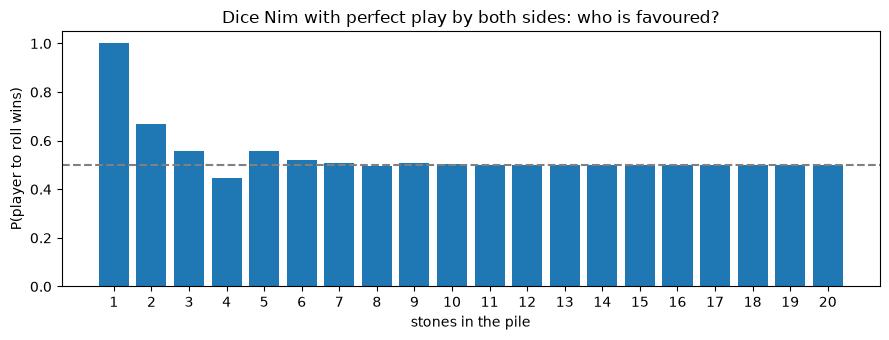

In [15]:
DIE = (1, 2, 3)                                      # equally likely faces

@lru_cache(maxsize=None)
def dice_nim_value(pile, player):
    # expectiminimax value for MAX (+1 = MAX wins, -1 = MIN wins); `player` is about to roll
    if pile == 0:                                    # the previous player took the last stone and won
        return -1.0 if player == "MAX" else 1.0
    other = "MIN" if player == "MAX" else "MAX"
    total = 0.0
    for roll in DIE:                                 # chance node: average over the die
        options = [dice_nim_value(pile - k, other) for k in range(1, min(roll, pile) + 1)]
        total += (max(options) if player == "MAX" else min(options)) / len(DIE)
    return total

def dice_nim_best_take(pile, player, roll):
    other = "MIN" if player == "MAX" else "MAX"
    takes = range(1, min(roll, pile) + 1)
    pick = max if player == "MAX" else min
    return pick(takes, key=lambda k: dice_nim_value(pile - k, other))

@lru_cache(maxsize=None)
def value_vs_random(pile, player):
    # exact value for MAX when MAX plays expectimax but MIN picks uniformly at random
    if pile == 0:
        return -1.0 if player == "MAX" else 1.0
    other = "MIN" if player == "MAX" else "MAX"
    total = 0.0
    for roll in DIE:
        if player == "MAX":
            k = dice_nim_best_take(pile, "MAX", roll)
            total += value_vs_random(pile - k, other) / len(DIE)
        else:
            takes = range(1, min(roll, pile) + 1)
            total += sum(value_vs_random(pile - k, other) for k in takes) / len(takes) / len(DIE)
    return total

def simulate(pile, min_policy, games, rng):
    # Monte Carlo check: play many games, MAX rolls first and plays expectimax
    wins = 0
    for _ in range(games):
        p, player = pile, "MAX"
        while True:
            roll = rng.choice(DIE)
            if player == "MAX":
                k = dice_nim_best_take(p, "MAX", roll)
            else:
                k = min_policy(p, roll, rng)
            p -= k
            if p == 0:
                wins += player == "MAX"
                break
            player = "MIN" if player == "MAX" else "MAX"
    return wins / games

expectimax_min = lambda p, roll, rng: dice_nim_best_take(p, "MIN", roll)
random_min = lambda p, roll, rng: rng.randint(1, min(roll, p))

rng = random.Random(0)
rows = []
for pile in (4, 7, 10, 15):
    pred_opt = (dice_nim_value(pile, "MAX") + 1) / 2            # convert value in [-1, 1] to a win probability
    pred_rnd = (value_vs_random(pile, "MAX") + 1) / 2
    sim_opt = simulate(pile, expectimax_min, 10_000, rng)
    sim_rnd = simulate(pile, random_min, 10_000, rng)
    se = 3 * math.sqrt(0.25 / 10_000)                            # 3 standard errors
    assert abs(sim_opt - pred_opt) < se and abs(sim_rnd - pred_rnd) < se
    rows.append({"pile": pile, "P(MAX wins) vs expectimax MIN: exact": round(pred_opt, 4),
                 "simulated": round(sim_opt, 4),
                 "P(MAX wins) vs random MIN: exact": round(pred_rnd, 4), "simulated ": round(sim_rnd, 4)})
display(pd.DataFrame(rows))

piles = range(1, 21)
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(piles, [(dice_nim_value(p, "MAX") + 1) / 2 for p in piles], color="tab:blue")
ax.axhline(0.5, color="gray", ls="--")
ax.set_xlabel("stones in the pile"); ax.set_ylabel("P(player to roll wins)")
ax.set_title("Dice Nim with perfect play by both sides: who is favoured?")
ax.set_xticks(list(piles)); plt.tight_layout(); plt.show()

**What just happened?** Expectimax solved Dice Nim exactly, and 10,000 simulated games per setting agree with the exact win probabilities to within 3 standard errors (checked with `assert`): an independent brute-force check. The bar chart shows an echo of ordinary Nim: without dice ("take 1 to 3 stones"), a pile that is a multiple of 4 is a certain loss for the player to move. With dice, the player to roll is slightly *disadvantaged* exactly at multiples of 4 (4, 8, 12, ...: below 50%) and slightly favoured otherwise, and for large piles everything converges to 50% because the dice wash out any plan.

**Complexity:** with $n$ distinct dice outcomes, expectiminimax takes $O(b^m n^m)$ time. Alpha-beta style pruning is possible at chance nodes only if utilities are **bounded** (then the average can be bounded before all children are seen). This is why backgammon programs search only a few plies and rely on a strong evaluation function: TD-Gammon (Tesauro, 1992) learned one by self-play with a neural network.

## 6. Monte Carlo Tree Search (MCTS)

*In plain words: judge a move by playing lots of quick random games from it, and spend more time on the promising moves.*

Alpha-beta needs a good evaluation function, and in **Go** nobody could write one: the value of a position depends on subtle, global patterns. MCTS (Coulom 2006; UCT by Kocsis & Szepesvári 2006) estimates the value of a state by **playing many random games (playouts) from it** and averaging the results. Instead of spreading playouts evenly, it grows a search tree towards the promising moves.

Each iteration has **four phases**:

```
 1. SELECTION        2. EXPANSION         3. SIMULATION          4. BACK-PROPAGATION
 from the root,      add one new child    play random moves      add the result to N (visits)
 follow the best     for an untried       until the game ends    and W (wins) of every node
 child by UCB1       move                 (a "playout")          on the path back to the root
```

**UCB1 selection rule** (Upper Confidence Bound applied to Trees, **UCT**): from node $n$, pick the child $c$ maximising

$$\text{UCB1}(c) = \underbrace{\frac{W(c)}{N(c)}}_{\text{exploitation: win rate}} + \; C \underbrace{\sqrt{\frac{\ln N(n)}{N(c)}}}_{\text{exploration: rarely tried moves get a bonus}}$$

where $W$ counts wins (draws count ½) for the player who made the move into $c$, $N$ is the visit count and $C \approx \sqrt{2}$ is the exploration constant. This is the **multi-armed bandit** trade-off from reinforcement learning ([`11_Reinforcement_Learning/07_multi_armed_bandits.ipynb`](../../11_Reinforcement_Learning/07_multi_armed_bandits.ipynb)).

When time runs out, play the root child with the **most visits** (more robust than the highest win rate).

 X | X | 2
 3 | O | 5
 6 | 7 | 8
to move: O


,visits,MCTS win rate for O,exact minimax value (X's view)
2,1574,0.547,0
3,94,0.239,1
5,86,0.221,1
6,99,0.253,1
7,62,0.145,1
8,85,0.218,1


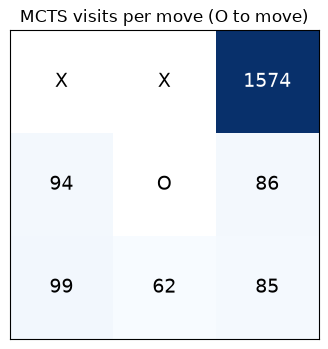

In [16]:
class MCTSNode:
    __slots__ = ("state", "parent", "move", "children", "untried", "N", "W")

    def __init__(self, state, parent=None, move=None):
        self.state, self.parent, self.move = state, parent, move
        self.children = []
        self.untried = [] if is_terminal(state) else actions(state)   # moves not expanded yet
        self.N = 0          # visits
        self.W = 0.0        # total reward for the player who made `move` (1 win, 0.5 draw, 0 loss)

def ucb1(child, parent_N, c):
    return child.W / child.N + c * math.sqrt(math.log(parent_N) / child.N)

def mcts(root_state, iterations, rng, c=math.sqrt(2)):
    root = MCTSNode(root_state)
    for _ in range(iterations):
        node = root
        # 1. selection: descend while the node is fully expanded
        while not node.untried and node.children:
            node = max(node.children, key=lambda ch: ucb1(ch, node.N, c))
        # 2. expansion: add one untried move
        if node.untried:
            a = node.untried.pop(rng.randrange(len(node.untried)))
            child = MCTSNode(result(node.state, a), node, a)
            node.children.append(child)
            node = child
        # 3. simulation: random playout to the end of the game
        s = node.state
        while not is_terminal(s):
            s = result(s, rng.choice(actions(s)))
        w = winner(s)
        # 4. back-propagation: update N and W along the path
        while node is not None:
            node.N += 1
            if node.parent is not None:
                mover = to_move(node.parent.state)         # who made the move into this node
                node.W += 1.0 if w == mover else (0.5 if w is None else 0.0)
            node = node.parent
    return root

def mcts_agent(iterations):
    def agent(b, rng):
        root = mcts(b, iterations, rng)
        return max(root.children, key=lambda ch: ch.N).move   # most-visited move
    agent.__name__ = f"MCTS {iterations}"
    return agent

# A tactical position: X threatens to complete the top row at square 2; O to move must block
pos = ("X", "X", " ",
       " ", "O", " ",
       " ", " ", " ")
print(show(pos)); print("to move:", to_move(pos))
root = mcts(pos, 2000, random.Random(0))
visits = {ch.move: ch.N for ch in root.children}
winrate = {ch.move: round(ch.W / ch.N, 3) for ch in root.children}
exact = {a: solve(result(pos, a)) for a in actions(pos)}
display(pd.DataFrame({"visits": visits, "MCTS win rate for O": winrate, "exact minimax value (X's view)": exact}).sort_index())

grid = np.full(9, np.nan)
for m, n in visits.items():
    grid[m] = n
fig, ax = plt.subplots(figsize=(3.6, 3.6))
ax.imshow(grid.reshape(3, 3), cmap="Blues")
for i in range(9):
    txt = pos[i] if pos[i] != " " else f"{int(grid[i])}"
    ax.text(i % 3, i // 3, txt, ha="center", va="center", fontsize=14,
            color="white" if pos[i] == " " and grid[i] > np.nanmax(grid) / 2 else "black")
ax.set_xticks([]); ax.set_yticks([]); ax.set_title("MCTS visits per move (O to move)")
plt.tight_layout(); plt.show()

**What just happened?** X threatens to complete the top row at square 2. The exact minimax values show that blocking at 2 holds the draw (value 0) and every other move loses (+1 = X wins). MCTS knows none of this; it only runs random playouts. Yet UCB1 quickly sends most of its 2,000 iterations to square 2, because playouts through the other moves keep ending in X wins. The win-rate column is an *average over playouts* (a noisy estimate), not a minimax value; with more iterations MCTS's choices converge to minimax choices (UCT is proven to converge for finite games).

Now let us measure that convergence, and compare MCTS with the perfect alpha-beta / minimax player.

In [17]:
# (a) How often does MCTS choose a minimax-optimal move? 60 random non-terminal positions.
def optimal_moves(b):
    vals = {a: solve(result(b, a)) for a in actions(b)}
    target = max(vals.values()) if to_move(b) == "X" else min(vals.values())
    return {a for a, v in vals.items() if v == target}

sample_rng = random.Random(42)
positions = sample_rng.sample([b for b in ALL_STATES if not is_terminal(b) and b.count(" ") >= 3], 60)
rows = []
for iters in (10, 50, 200, 1000):
    rng = random.Random(iters)
    t0 = time.perf_counter()
    agree = sum(mcts_agent(iters)(b, rng) in optimal_moves(b) for b in positions)
    rows.append({"MCTS iterations": iters, "optimal move chosen (out of 60)": agree,
                 "% optimal": round(100 * agree / 60, 1),
                 "ms per move": round(1000 * (time.perf_counter() - t0) / 60, 2)})
agree_df = pd.DataFrame(rows)
display(agree_df)

,MCTS iterations,optimal move chosen (out of 60),% optimal,ms per move
0,10,50,83.3,0.57
1,50,58,96.7,2.44
2,200,60,100.0,8.12
3,1000,60,100.0,40.31


In [18]:
# (b) MCTS against the perfect player (minimax / alpha-beta), 20 games each, alternating colours
def ttt_match(agent_a, agent_b, games, seed):
    rng = random.Random(seed)
    res = Counter()
    for g in range(games):
        if g % 2 == 0:
            u = utility(play_ttt(agent_a, agent_b, rng))        # A is X
        else:
            u = -utility(play_ttt(agent_b, agent_a, rng))       # A is O
        res[{1: "A wins", 0: "draw", -1: "B wins"}[u]] += 1
    return {"A": agent_a.__name__, "B": agent_b.__name__, "games": games,
            "A wins": res["A wins"], "draws": res["draw"], "B wins": res["B wins"]}

perfect_agent.__name__ = "perfect (minimax)"
random_agent.__name__ = "random"
rows = [ttt_match(mcts_agent(n), random_agent, 20, 10 + n) for n in (25, 200)]
rows += [ttt_match(mcts_agent(n), perfect_agent, 20, 20 + n) for n in (10, 50, 200, 1000)]
mcts_df = pd.DataFrame(rows)
display(mcts_df)

,A,B,games,A wins,draws,B wins
0,MCTS 25,random,20,19,1,0
1,MCTS 200,random,20,18,2,0
2,MCTS 10,perfect (minimax),20,0,4,16
3,MCTS 50,perfect (minimax),20,0,13,7
4,MCTS 200,perfect (minimax),20,0,17,3
5,MCTS 1000,perfect (minimax),20,0,20,0


**What just happened?**
- (a) With only 10 iterations MCTS picked a minimax-optimal move in 50 of the 60 positions; with 50 iterations in 58; with 200 or more iterations in all 60.
- (b) Against the perfect player, MCTS with 10 iterations lost 16 of 20 games; with 50 iterations 7; with 200 iterations 3; with 1,000 iterations it drew all 20 (nobody can beat a perfect tic-tac-toe player). Against a random player even MCTS with 25 iterations won 19 of 20.

### Alpha-beta versus MCTS

| | Alpha-beta (depth-limited) | MCTS (UCT) |
|---|---|---|
| Needs an evaluation function? | yes (or search to the end) | no: random playouts estimate value (AlphaZero replaces them with a value network) |
| Tree shape | uniform depth, pruned | asymmetric: deep where promising, shallow elsewhere |
| Anytime? | at the end of each iterative-deepening iteration | yes: stop after any iteration |
| Guarantees | exact minimax value to the searched depth | converges to minimax as iterations → ∞ |
| Weakness | high branching factor (Go: ~250) | narrow tactical traps that random playouts miss |
| Famous users | Deep Blue, Stockfish (chess) | AlphaGo, AlphaZero, MuZero, Leela Chess Zero |

For tic-tac-toe, exact solving is trivial, so alpha-beta is the right tool. MCTS shines when the branching factor is huge and no good evaluation function is known.

## 7. History: from Deep Blue to MuZero

*In plain words: how these ideas beat human champions, and what each famous system really did.*

| Year | System | What it did | Search | Knowledge |
|---|---|---|---|---|
| 1950 | Shannon's paper "Programming a Computer for Playing Chess" | proposed depth-limited minimax with an evaluation function | minimax | hand-written evaluation |
| 1992 | **TD-Gammon** (Tesauro, IBM) | backgammon near top human level | 2-3 ply expectiminimax | neural network evaluation learned by self-play (temporal-difference learning) |
| 1994 / 2007 | **Chinook** (Schaeffer, Univ. of Alberta) | first program to win a human world championship title (checkers, 1994); in 2007 the team proved checkers is a **draw** with perfect play | alpha-beta + endgame databases | hand-written |
| 1997 | **Deep Blue** (IBM) | beat world champion Garry Kasparov 3½–2½ in a six-game match (May 1997), after losing their 1996 match 2–4 | parallel alpha-beta on custom chess chips, about 200 million positions per second | hand-tuned evaluation, opening book, endgame databases |
| 2016 | **AlphaGo** (DeepMind) | beat Fan Hui 5–0 (October 2015, published January 2016) and Lee Sedol 4–1 (March 2016) at Go | MCTS guided by neural networks | policy network trained on human games then improved by self-play RL; value network; fast rollout policy |
| 2017 | **AlphaGo Zero** (DeepMind) | learned Go from scratch, no human games; beat the Lee Sedol version 100–0 | MCTS, no random rollouts | one network (policy + value) trained only by self-play |
| 2017 / 2018 | **AlphaZero** (DeepMind; preprint 2017, *Science* 2018) | the same algorithm mastered chess, shogi and Go; beat Stockfish (chess), Elmo (shogi) and AlphaGo Zero (Go) | MCTS with a PUCT rule guided by the network; searches tens of thousands of positions per second, versus tens of millions for Stockfish | self-play only, given the rules |
| 2019 / 2020 | **MuZero** (DeepMind; preprint 2019, *Nature* 2020) | matched AlphaZero in chess, shogi and Go and set a new state of the art on Atari, **without being given the rules** | MCTS inside a **learned model** of the game | learns representation, dynamics and prediction networks |

Some accurate footnotes:
- Deep Blue was not "AI that learned chess"; it was brute-force alpha-beta search on special hardware with an expert-tuned evaluation function.
- AlphaGo's MCTS is still tree search; the networks replace the hand-written evaluation function (value network) and focus the search on plausible moves (policy network).
- Alpha-beta did not die: since 2020, Stockfish uses **NNUE**, a small neural evaluation function, inside classic alpha-beta search, and it is among the strongest chess engines.
- For imperfect-information games like poker, minimax does not apply directly. Libratus (2017, heads-up no-limit Texas hold'em) and Pluribus (2019, six-player) from Carnegie Mellon (Pluribus with Facebook AI) used counterfactual regret minimisation instead.

## 8. Play against the AI yourself

*In plain words: a function you can call to play against the programs in this notebook.*

The function below lets you play tic-tac-toe against the perfect minimax player, or Connect-4 against the depth-limited alpha-beta player. It uses `input()`, so it is **not called in this notebook**. Run `play()` or `play("connect4", depth=5)` in a new cell when you want to try.

In [19]:
def play(game="tictactoe", human_first=True, depth=4, seed=None):
    # Interactive game against the AI. Type a square (0-8) or a column (0-5) when asked.
    rng = random.Random(seed)
    if game == "tictactoe":
        b = EMPTY_BOARD
        human = "X" if human_first else "O"
        while not is_terminal(b):
            print(show(b), "\n")
            if to_move(b) == human:
                move = None
                while move not in actions(b):
                    try:
                        move = int(input(f"You are {human}. Your move (one of {actions(b)}): "))
                    except ValueError:
                        move = None
            else:
                move = perfect_agent(b, rng)
                print("AI plays", move)
            b = result(b, move)
        print(show(b)); print("Result:", {None: "draw"}.get(winner(b), f"{winner(b)} wins"))
    elif game == "connect4":
        cols, player = new_board(), 1
        human = 1 if human_first else 2
        ai = ai_agent(depth)
        while legal_moves(cols):
            print(board_str(cols), "\n")
            if player == human:
                c = None
                while c not in legal_moves(cols):
                    try:
                        c = int(input(f"You are {'X' if human == 1 else 'O'}. Column {legal_moves(cols)}: "))
                    except ValueError:
                        c = None
            else:
                c = ai(cols, player, rng)
                print("AI drops in column", c)
            cols[c].append(player)
            if is_winning_drop(cols, c):
                print(board_str(cols)); print("You win!" if player == human else "AI wins!")
                return
            player = 3 - player
        print(board_str(cols)); print("Draw!")
    else:
        raise ValueError("game must be 'tictactoe' or 'connect4'")

print("play() is defined. Call play() or play('connect4') yourself to play.")

play() is defined. Call play() or play('connect4') yourself to play.


## 9. Summary table

*In plain words: all the game-search methods side by side.*

| Algorithm | Game type | Time | Space | Exact? | Needs |
|---|---|---|---|---|---|
| Minimax | 2-player, deterministic, perfect information | $O(b^m)$ | $O(bm)$ | yes | full tree or cut-off |
| Alpha-beta | same | best $O(b^{m/2})$, random order about $O(b^{3m/4})$, worst $O(b^m)$ | $O(bm)$ | same value as minimax | good move ordering |
| Depth-limited (H-minimax) | same, large games | $O(b^d)$ for depth $d$ (less with alpha-beta) | $O(bd)$ | no, only as good as EVAL | evaluation function |
| Expectiminimax | with dice / chance | $O(b^m n^m)$ for $n$ chance outcomes | $O(bm)$ | yes (expected value) | probabilities; EVAL on the right scale |
| MCTS (UCT) | any, especially huge $b$ | proportional to iterations × playout length | size of the grown tree | converges to minimax | a simulator (and ideally a learned policy/value) |

## 🔗 How this connects to modern AI

- **AlphaZero-style MCTS + neural networks** is reinforcement learning with search: see [`11_Reinforcement_Learning/01_rl_fundamentals.ipynb`](../../11_Reinforcement_Learning/01_rl_fundamentals.ipynb) and [`11_Reinforcement_Learning/06_advanced_rl.ipynb`](../../11_Reinforcement_Learning/06_advanced_rl.ipynb). The UCB1 rule comes from bandits: [`11_Reinforcement_Learning/07_multi_armed_bandits.ipynb`](../../11_Reinforcement_Learning/07_multi_armed_bandits.ipynb).
- **Search over LLM reasoning:** "tree of thoughts" and MCTS-style methods explore several reasoning paths and score them with a value model or verifier, the same select-expand-evaluate-backup loop: see [`08_LLM/18_reasoning_models.ipynb`](../../08_LLM/18_reasoning_models.ipynb).
- **Adversarial thinking in ML:** GANs train a generator against a discriminator (a minimax objective, [`05_Deep_Learning/06_generative_models.ipynb`](../../05_Deep_Learning/06_generative_models.ipynb)), and robust training / red-teaming assumes a worst-case opponent.
- **Game engines** for chess, Go and video-game AI still use exactly these algorithms, now with learned evaluation functions.

## Recap

- A game is a search problem with an opponent: $S_0$, TO-MOVE, ACTIONS, RESULT, IS-TERMINAL, UTILITY. Zero-sum means one number describes the outcome for both players.
- **Minimax** backs up values from the leaves (max for MAX, min for MIN): $O(b^m)$ time, $O(bm)$ space. Tic-tac-toe has 549,946 tree nodes, 5,478 positions, and minimax value 0: a draw.
- **Alpha-beta** returns the same root value while pruning branches that cannot matter; with perfect ordering it examines $b^{\lceil d/2 \rceil} + b^{\lfloor d/2 \rfloor} - 1$ leaves, so it can search about twice as deep.
- Large games need a **depth limit + evaluation function**; watch for the horizon effect; use iterative deepening, quiescence search and transposition tables.
- **Expectiminimax** averages over chance nodes; the scale of the evaluation function matters.
- **MCTS** = selection (UCB1) + expansion + random playout + back-propagation; it needs no evaluation function and converges to minimax.
- Deep Blue (1997) was alpha-beta + hardware; AlphaGo (2016), AlphaZero (2017/2018) and MuZero (2019/2020) are MCTS + deep networks trained by self-play.

## Practice problems

**1. (Easy, by hand)** A MAX root has two MIN children. The first MIN child has leaves (5, 1, 9), the second has leaves (4, 6). What is the minimax value, and which leaves does alpha-beta prune (left-to-right order)?

<details><summary>Show solution</summary>

First MIN child = min(5, 1, 9) = 1, so α = 1 at the root. Second MIN child: first leaf 4 gives "≤ 4", which is not ≤ α = 1, so no cut; then 6, so it equals 4. Root = max(1, 4) = **4**. Nothing is pruned. (If the children were ordered the other way round, (4, 6) first, the root would get α = 4, and in (5, 1, 9) the leaf 1 ≤ 4 would cut off the 9.) Move ordering matters!
</details>

**2. (Easy, conceptual)** Why does alpha-beta not change the minimax value at the root, even though it does not compute the exact value of every node?

<details><summary>Show solution</summary>

A subtree is pruned only when we have proved that its value cannot affect the decision: at a MIN node with value ≤ α, MAX already has an alternative at least as good higher up, so MAX will never choose the path to this node (symmetrically for β). The pruned node's returned value is just a bound, but bounds are enough to know it is not the best choice, so the root's maximum is unchanged.
</details>

**3. (Medium, conceptual)** With perfect move ordering alpha-beta needs about $b^{m/2}$ nodes. If a minimax program can search 6 plies deep in the time allowed, about how deep can a perfectly ordered alpha-beta program search in the same time?

<details><summary>Show solution</summary>

$b^{m/2} = b^6$ when $m = 12$: about **12 plies**, twice as deep. That is why alpha-beta was such a big deal for chess.
</details>

**4. (Medium, coding)** Of the 5,478 reachable tic-tac-toe positions, how many are terminal, and how many of those are X wins, O wins and draws? Use `ALL_STATES`.

<details><summary>Show solution</summary>

```python
terminal = [b for b in ALL_STATES if is_terminal(b)]
outcome = Counter(winner(b) or "draw" for b in terminal)
print(len(terminal), dict(outcome))
assert len(terminal) == 958 and outcome["X"] == 626 and outcome["O"] == 316 and outcome["draw"] == 16
```
958 terminal positions: 626 X wins, 316 O wins and only 16 drawn full boards.
</details>

**5. (Medium, coding)** Write `negamax_ttt(b)` for tic-tac-toe that returns the value **for the player to move** using a single `max`, and check that `negamax_ttt(b) == (solve(b) if to_move(b) == "X" else -solve(b))` for every non-terminal position.

<details><summary>Show solution</summary>

```python
@lru_cache(maxsize=None)
def negamax_ttt(b):
    if is_terminal(b):
        u = utility(b)                                  # +1 means X won
        return u if to_move(b) == "X" else -u           # convert to the view of the player to move
    return max(-negamax_ttt(result(b, a)) for a in actions(b))

for b in ALL_STATES:
    if not is_terminal(b):
        assert negamax_ttt(b) == (solve(b) if to_move(b) == "X" else -solve(b))
print("negamax agrees with minimax everywhere")
```
</details>

**6. (Medium, conceptual)** In UCT, what happens if the exploration constant is $C = 0$? What if $C$ is huge?

<details><summary>Show solution</summary>

With $C = 0$ the search is purely greedy: after each move has been tried once, it keeps choosing the move with the best current win rate and may never revisit a move that was unlucky in its first playout, so it can lock onto a bad move. With a huge $C$ the exploration term dominates, visits become nearly uniform, and MCTS degenerates into flat Monte Carlo sampling that does not focus on good lines. $C \approx \sqrt{2}$ is the theoretical choice for rewards in $[0, 1]$; in practice it is tuned.
</details>

**7. (Hard, coding)** Write a depth-limited minimax for tic-tac-toe with the evaluation "number of lines still open for X minus number of lines still open for O" (a line is open for X if it has no O). Check that with depth 9 it returns exactly `solve(b)` for every position, and count how many positions get a *different* best move at depth 2.

<details><summary>Show solution</summary>

```python
def open_lines_eval(b):
    open_x = sum(1 for line in LINES if all(b[i] != "O" for i in line))
    open_o = sum(1 for line in LINES if all(b[i] != "X" for i in line))
    return (open_x - open_o) / 10                      # scaled into (-1, 1) so a real win (+-1) dominates

def h_minimax(b, depth):
    if is_terminal(b):
        return utility(b)
    if depth == 0:
        return open_lines_eval(b)
    vals = [h_minimax(result(b, a), depth - 1) for a in actions(b)]
    return max(vals) if to_move(b) == "X" else min(vals)

late = [b for b in ALL_STATES if b.count(" ") <= 5]   # keep it quick
for b in late:
    assert h_minimax(b, 9) == solve(b)

def best_move(b, value_fn):
    acts = actions(b)
    pick = max if to_move(b) == "X" else min
    return pick(acts, key=lambda a: value_fn(result(b, a)))

different = sum(best_move(b, lambda s: h_minimax(s, 1)) not in optimal_moves(b)
                for b in late if not is_terminal(b))
print("positions where the depth-2 search picks a non-optimal move:", different)
```
At full depth the evaluation function is never used, so the values are exact. At depth 2 (the move plus one reply) the heuristic sometimes prefers a move that is not minimax-optimal: the horizon effect in miniature.
</details>

**8. (Hard, conceptual)** Explain why expectimax cannot use ordinary alpha-beta pruning at chance nodes, and what extra assumption makes some pruning possible.

<details><summary>Show solution</summary>

A chance node's value is an average of all its children; one bad child does not decide it, so you cannot stop after seeing a single child the way a MIN node can. If utilities are **bounded**, say in $[-1, 1]$, then after seeing some children you can bound the average: the unseen children contribute at most their probability times the maximum utility. If even that upper bound is below α (or the lower bound above β), the chance node can be pruned. This is the idea behind *\*-minimax* (Star1/Star2, Ballard 1983).
</details>

## Further reading

- Russell & Norvig, *Artificial Intelligence: A Modern Approach*, 4th ed. (2020), Chapter 5 "Adversarial Search and Games" (minimax, alpha-beta, MCTS, stochastic games, history).
- Knuth & Moore, "An Analysis of Alpha-Beta Pruning", *Artificial Intelligence* 6 (1975).
- Browne et al., "A Survey of Monte Carlo Tree Search Methods", *IEEE Transactions on Computational Intelligence and AI in Games* (2012).
- Silver et al., "Mastering the game of Go without human knowledge", *Nature* (2017), and "A general reinforcement learning algorithm that masters chess, shogi, and Go through self-play", *Science* (2018); Schrittwieser et al., "Mastering Atari, Go, chess and shogi by planning with a learned model", *Nature* (2020).
- Free online: the [Chess Programming Wiki](https://www.chessprogramming.org/) (alpha-beta, move ordering, transposition tables, NNUE) and the AIMA code repository [aima-python](https://github.com/aimacode/aima-python) (`games.py`).

## Next notebook

[`06_constraint_satisfaction.ipynb`](06_constraint_satisfaction.ipynb): problems defined by variables and constraints (map colouring, Sudoku, timetabling), solved with backtracking, constraint propagation and min-conflicts.

In [20]:
print(f"Notebook finished in {time.time() - NOTEBOOK_START:.1f} s")

Notebook finished in 73.1 s
